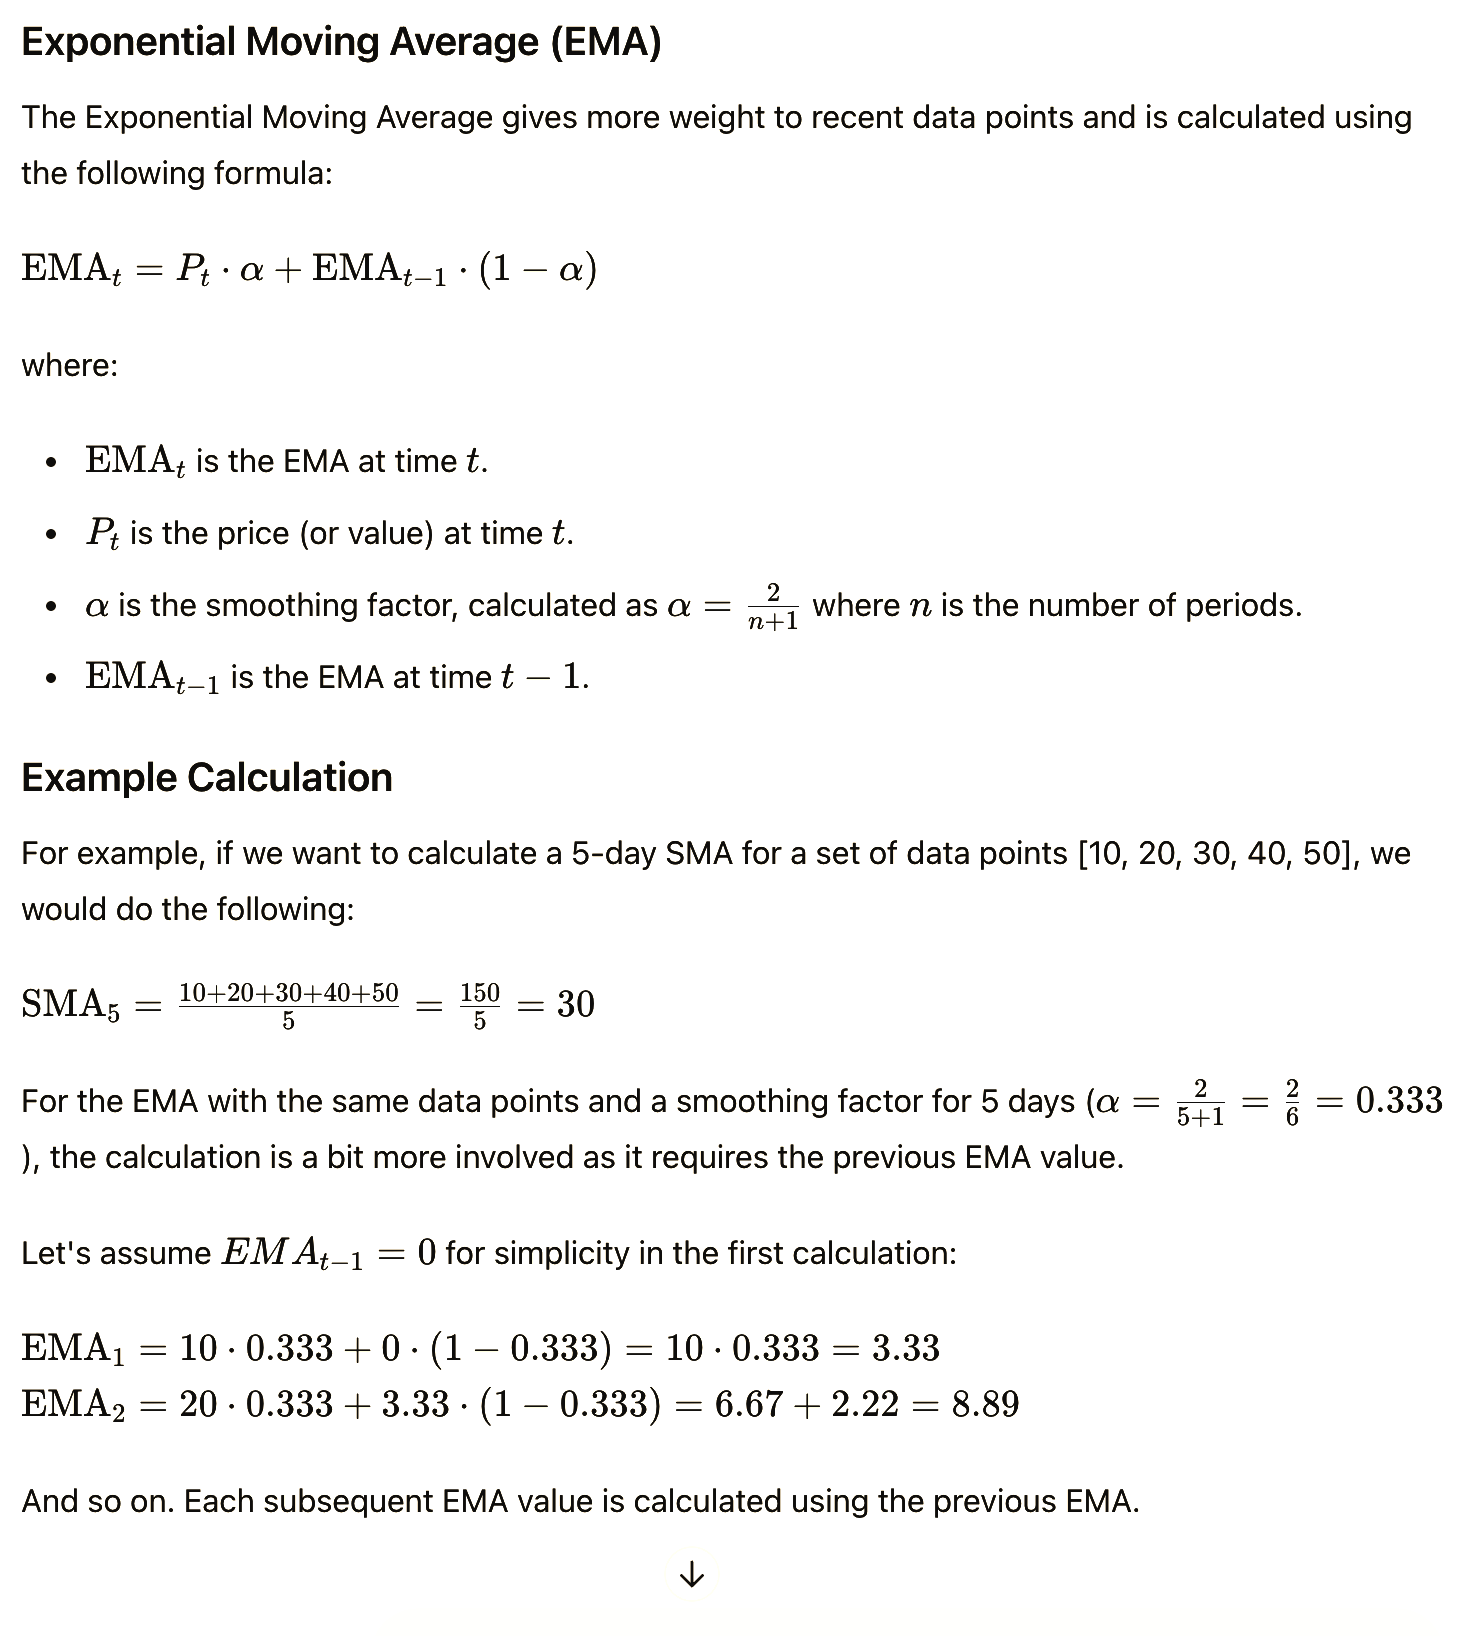

$\alpha_t = x_t \times \beta + \alpha_{t-1} \times (1-\beta)$

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

# Generate sample data
np.random.seed(0)
dates = pd.date_range('20230101', periods=100)
data = np.random.randn(100).cumsum()

# Create a DataFrame
df = pd.DataFrame(data, index=dates, columns=['Value'])

# Function to calculate and plot moving averages
def plot_moving_averages(alpha):
    df['SMA'] = df['Value'].rolling(window=10).mean()
    df['EMA'] = df['Value'].ewm(alpha=alpha).mean()

    plt.figure(figsize=(14, 7))
    plt.plot(df.index, df['Value'], label='Original Data', color='blue')
    plt.plot(df.index, df['SMA'], label='Simple Moving Average (10 days)', color='orange')
    plt.plot(df.index, df['EMA'], label=f'Exponential Moving Average (alpha={alpha:.2f})', color='green')

    plt.title('Moving Averages vs Original Data')
    plt.xlabel('Date')
    plt.ylabel('Value')
    plt.legend()
    plt.grid(True)
    plt.show()

# Create an interactive plot with a slider for alpha
interact(plot_moving_averages, alpha=FloatSlider(value=0.1, min=0.01, max=1.0, step=0.01, description='Alpha'))

interactive(children=(FloatSlider(value=0.1, description='Alpha', max=1.0, min=0.01, step=0.01), Output()), _d…

<function __main__.plot_moving_averages(alpha)>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

# Generate sample data
np.random.seed(0)
dates = np.arange('2023-01-01', '2023-04-11', dtype='datetime64[D]')
data = np.random.randn(len(dates)).cumsum()

# Function to calculate Simple Moving Average
def calculate_sma(data, window):
    sma = []
    for i in range(len(data)):
        if i < window:
            sma.append(np.nan)
        else:
            sma.append(np.mean(data[i-window:i]))
    return np.array(sma)

# Function to calculate Exponential Moving Average
def calculate_ema(data, alpha):
    ema = []
    ema.append(data[0])  # EMA starts with the first data point
    for i in range(1, len(data)):
        ema.append(alpha * data[i] + (1 - alpha) * ema[-1])
    return np.array(ema)

# Function to plot moving averages
def plot_moving_averages(alpha):
    sma = calculate_sma(data, window=10)
    ema = calculate_ema(data, alpha)

    plt.figure(figsize=(14, 7))
    plt.plot(dates, data, label='Original Data', color='blue')
    plt.plot(dates, sma, label='Simple Moving Average (10 days)', color='orange')
    plt.plot(dates, ema, label=f'Exponential Moving Average (alpha={alpha:.2f})', color='green')

    plt.title('Moving Averages vs Original Data')
    plt.xlabel('Date')
    plt.ylabel('Value')
    plt.legend()
    plt.grid(True)
    plt.show()

# Create an interactive plot with a slider for alpha
interact(plot_moving_averages, alpha=FloatSlider(value=0.1, min=0.01, max=1.0, step=0.01, description='Alpha'))

interactive(children=(FloatSlider(value=0.1, description='Alpha', max=1.0, min=0.01, step=0.01), Output()), _d…

<function __main__.plot_moving_averages(alpha)>